# Heartsteps Matrix Completion using Nearest Neighbor Strategies

## Motivation

Within many real-world applications, there is an interest in measuring reaction to stimuli over time. For example, in a medical trial for a new drug, participants might receive dosages at various times over the trial period. This yields a unique structure of data, where patients (units) receive drug dosages (treatments) at certain times (decision points) while being monitored in between dosages for changes in health condition (outcomes). 

Consider a more general case: there are $N$ units who undergo $T$ potential treatment periods. At treatment period $t$, a unit $i$ receives treatment if $A_{i, t} = 1$ and does not if $A_{i, t} = 0$. Suppose for each combination of unit $i$ and treatment period $T$, there are $n$ measurements of the characteristics of unit $i$ at this treatment period. We denote these measurements as $X_k(i, t) \in \mathbb{R}^d$ for $k \in [n]$. Each $X_k(i, t)$ is sampled from a unit-treatment period specific distribution $\mu_{i, t}$. To estimate the effect of the treatment strategy across $T$ periods at a unit-treatment level of specificity, we must consider the counterfactuals: the measurements $X_k(i, t)$ such that the treatment $A_{i, t}$ is the opposite of what was observed.

To be continued...

## Structure

We make the assumption that the data is stored in a format similar to the Heartsteps dataset shown below. Each row represents a user and a segment of time (in the Heartsteps case, every 5 minutes from 9:05am-9:00pm). Each row indicates the outcome of interest and whether or not the treatment was applied during that measurement time. 

`transfom_dnn` takes in data formatted like this and transforms it into usable arrays that match the problem description above. More specifically, it creates 2 matrices, $A$ and $M$ both of size $N$ x $T$. As above, $A$ is the treatment matrix, where $A_{ij} = 1$ when unit $i$ received the treatment at treatment period $j$ and $A_{ij} = 0$ otherwise. Each entry of $M$ is an array of length $n$ that contains the measurements of the outcome of interest. 

## Data

In [2]:
import numpy as np
import pandas as pd
from itertools import chain
import datetime
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt

In [3]:
# read in Heartsteps dataset
df_hs = pd.read_csv("data_use.csv")
df_hs

,user.index,date,time,5min_datetime,steps,rolling_sum,rt,sugg.decision.5min,send.sedentary,availability
0,1,7/22/2015,9:05:00,NaN,0,0,1,NaN,0,1
1,1,7/22/2015,9:10:00,NaN,0,0,1,NaN,0,1
2,1,7/22/2015,9:15:00,NaN,0,0,1,NaN,0,1
3,1,7/22/2015,9:20:00,NaN,0,0,1,NaN,0,1
4,1,7/22/2015,9:25:00,NaN,0,0,1,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...
228235,37,1/26/2016,20:40:00,NaN,0,0,1,NaN,0,1
228236,37,1/26/2016,20:45:00,NaN,0,0,1,NaN,0,1
228237,37,1/26/2016,20:50:00,NaN,0,0,1,NaN,0,1
228238,37,1/26/2016,20:55:00,NaN,0,0,1,NaN,0,1


In [4]:
# format 'date' as datetime objects
#df_hs['date'] = pd.to_datetime(df_hs['date'])
df_hs['date_time'] = df_hs['date'] + ' ' + df_hs['time']
df_hs['date_time'] = pd.to_datetime(df_hs['date_time'])
df_hs['treatment'] = df_hs['send.sedentary']

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26608\98446096.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])


<Axes: xlabel='date'>

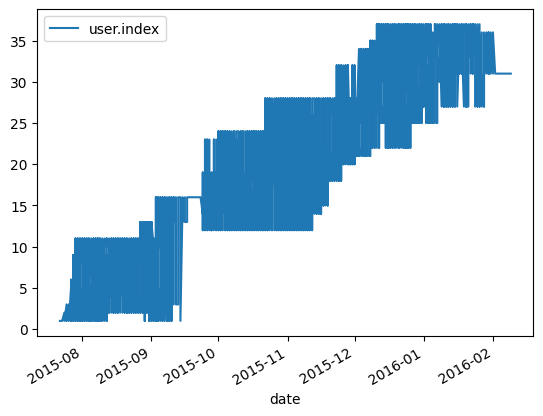

In [5]:
# checking unit overlap for better consistency
df_time_ind = df_hs[["user.index", "date"]]
df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])

df_time_ind.plot("date","user.index")
# range df
#max(df_time_ind[df_time_ind["user.index"] == 1]["date"])


## Define `transform_dnn`

### First pass: assuming all trials start at the same time

In [6]:
def transform_dnn(df, day_partitions = 4, day_measure = 144, units = 37):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    # first, find the maximum trial length in days
    # units are 1-indexed
    max_days = 0
    num_days = []
    for i in range(1, units + 1):
        len_i = len(df[df['user.index'] == i]) // day_measure
        num_days.append(len_i)
        if len_i > max_days:
            max_days = len_i
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        # pad first to max trial length to maintain partition size across units
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
        if num_days[i] < max_days:
            # pad with 0s, step values are masked by trt
            pad = np.empty((max_days - num_days[i]) * day_measure)
            pad.fill(np.nan)
            trial_steps = np.append(trial_steps, pad)
            pad_trt = np.zeros((max_days - num_days[i]) * day_measure)
            trial_trt = np.append(trial_trt, pad_trt)
            
        # first split into days, then into partitions
        lst_days = np.split(trial_steps, max_days)
        parts = np.array([np.split(x, day_partitions) for x in lst_days])
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.split(trial_trt, max_days)
        parts_trt = np.array([np.split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        unit_trt_agg = unit_trt.any(axis = 1).astype(int)
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

### Second pass: maintaining original time structure

One key observation from our preliminary data analysis (see Fig. 1) is that units start their trials at different times and have varying trial lengths, creating a "chunk"-like structure. To preserve time-specific effects (such as seasonal changes or disparities in weekday vs. weekend behavior), we add to our definition of `transform_dnn`. We wish to maintain the same chronological order as the input data. Thus, we dynamically pad each user's trial period on both ends to stretch from the minimum trial start date to the maximum trial start date. This padding will create additional missingness in the off-diagonals, which we will investigate later. Additionally, we add `np.nan` entries for days within the trial period that do not have observations, which improves upon the previous approach of ignoring such gaps. 

In [7]:
def pad_dates(df, freq = '5T', range_begin = '09:05:00', range_end = '21:00:00'):
    """
    Extend trial dates in df['date'] so that each unit has max(df['date']) - min(df['date'])
    days in a trial. Observations that are synthetically created in this process are imputed with
    np.nan
    
    Parameters:
    ----------
    df : a Dataframe with columns `date`, `treatment`, `steps`, and `user.index`
    
    Returns:
    ----------
    df_extend : the extended Dataframe described above
    """
    start_day = min(df['date_time'])
    end_day = max(df['date_time'])
    df = df.set_index('date_time')

    
    def reind_id(df_u):
        rng = pd.date_range(start_day, end_day, freq = freq)
        if range_begin is not None:
            rng = rng[rng.indexer_between_time(range_begin, range_end)]
        df_reind = df_u.reindex(rng)
        df_reind['user.index'] = df_reind['user.index'].ffill().bfill()
        return df_reind
        
    
    df_final = df.groupby('user.index', group_keys = False).apply(lambda df_u:reind_id(df_u))
    df_final = df_final.reset_index(names = "date_time")
    
    df_final['user.index'] = df_final['user.index'].astype("int32")
    
    return df_final[['user.index','treatment', 'steps']]
    
        
def transform_dnn_pad(df, day_partitions = 4, day_measure = 144, units = 37, freq ="5T", 
                      range_begin = '09:05:00', range_end ='21:00:00'):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    df = pad_dates(df, freq, range_begin, range_end)
    
    # all days now have the same length
    max_days = len(df[df['user.index'] == 1]) // day_measure
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
            
        # first split into days, then into partitions
        lst_days = np.array_split(trial_steps, max_days)
        parts = np.array([np.array_split(x, day_partitions) for x in lst_days], dtype = object)
        #print(parts)
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.array_split(trial_trt, max_days)
        parts_trt = np.array([np.array_split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        unit_trt_agg = np.nan_to_num(unit_trt, nan = 0).any(axis = 1).astype(int)
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

## Testing `transform_dnn` with simulated symmetrical data

We create a small test dataset as a proof of concept of the above data transformation. This data set will have 3 units over a time span of 4 days, with 12 measurements a day. We partition each day into 3 segments (4 measurements per partition). The treatment is randomly applied across each day and time span. This is a simpler example than the actual use case, as the number of days within the trial is consistent for all users. See the section below for a more complex example.

In [253]:
# create test set

# user inds
u1 = np.repeat(1, 12 * 4)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 4)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u2_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u3_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

# time of measurements
single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_symtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"]) 
df_symtest["date_time"] = pd.concat([single, single, single]).reset_index(drop = "True")

df_symtest

,user.index,steps,treatment,date_time
0,1,9,0,2024-06-14 00:00:00
1,1,5,0,2024-06-14 02:00:00
2,1,8,1,2024-06-14 04:00:00
3,1,3,1,2024-06-14 06:00:00
4,1,6,0,2024-06-14 08:00:00
...,...,...,...,...
139,3,5,0,2024-06-17 14:00:00
140,3,9,0,2024-06-17 16:00:00
141,3,3,0,2024-06-17 18:00:00
142,3,1,0,2024-06-17 20:00:00


Now that we have created our test set, we can use `transform_dnn_pad` to demonstrate the desired transformation properties.

In [247]:
M, A = transform_dnn_pad(df_symtest, day_partitions = 3, day_measure = 12, units = 3, freq = "2h", range_begin = None)

In [248]:
M

array([[[2., 6., 9., 1.],
        [5., 8., 5., 8.],
        [5., 8., 9., 3.],
        [2., 1., 4., 8.],
        [6., 8., 6., 5.],
        [1., 8., 6., 7.],
        [3., 8., 3., 5.],
        [3., 4., 5., 2.],
        [9., 1., 8., 8.],
        [9., 6., 4., 5.],
        [5., 5., 9., 8.],
        [9., 7., 7., 4.]],

       [[2., 6., 7., 9.],
        [1., 5., 3., 4.],
        [2., 6., 6., 8.],
        [3., 3., 8., 3.],
        [7., 5., 7., 2.],
        [4., 4., 9., 9.],
        [3., 7., 2., 2.],
        [9., 4., 1., 7.],
        [2., 1., 6., 5.],
        [3., 9., 4., 1.],
        [9., 9., 4., 2.],
        [6., 4., 7., 2.]],

       [[7., 0., 2., 1.],
        [9., 7., 9., 9.],
        [3., 8., 6., 7.],
        [0., 3., 6., 2.],
        [3., 4., 7., 7.],
        [7., 9., 3., 9.],
        [7., 8., 7., 0.],
        [8., 1., 8., 9.],
        [7., 6., 9., 1.],
        [2., 8., 9., 9.],
        [2., 5., 7., 2.],
        [3., 0., 6., 8.]]])

In [249]:
A

array([[1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1],
       [0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0],
       [1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0]])

## Testing `transform_dnn` on simulated asymmetrical data

Next, we test the function on a dataset with asymmetrical trial periods. As before, we will have 3 units, but this time, one of the units has a longer 6 day trial period. The remaining units have a 4 day trial period. There are still 12 measurements a day, and each day has 3 segments.

In [261]:
# create test set
# user inds, u1 has 6 day trial period
u1 = np.repeat(1, 12 * 6)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 6)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1], 12 * 6, p=[0.8, 0.2])
u2_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u3_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
longer = pd.Series(pd.date_range("2024-06-14", "2024-06-20", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_asymtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
df_asymtest["date_time"] = pd.concat([longer, single, single]).reset_index(drop = "True")
df_asymtest

,user.index,steps,treatment,date_time
0,1,7,0,2024-06-14 00:00:00
1,1,6,1,2024-06-14 02:00:00
2,1,9,0,2024-06-14 04:00:00
3,1,1,0,2024-06-14 06:00:00
4,1,9,0,2024-06-14 08:00:00
...,...,...,...,...
163,3,1,0,2024-06-17 14:00:00
164,3,5,0,2024-06-17 16:00:00
165,3,9,0,2024-06-17 18:00:00
166,3,5,1,2024-06-17 20:00:00


In [266]:
M_a, A_a = transform_dnn_pad(df_asymtest, day_partitions = 3, day_measure = 12, units = 3, freq = "2h", range_begin = None)

In [267]:
M_a

array([[[ 7.,  6.,  9.,  1.],
        [ 9.,  3.,  2.,  3.],
        [ 6.,  1.,  1.,  7.],
        [ 1.,  2.,  4.,  9.],
        [ 4.,  6.,  4.,  6.],
        [ 3.,  8.,  3.,  4.],
        [ 9.,  7.,  9.,  6.],
        [ 1.,  5.,  5.,  8.],
        [ 6.,  2.,  6.,  6.],
        [ 1.,  7.,  8.,  1.],
        [ 1.,  2.,  6.,  1.],
        [ 7.,  5.,  3.,  1.],
        [ 8.,  4.,  9.,  9.],
        [ 7.,  8.,  4.,  6.],
        [ 2.,  1.,  4.,  4.],
        [ 5.,  1.,  8.,  5.],
        [ 4.,  6.,  8.,  1.],
        [ 4.,  5.,  1.,  6.]],

       [[ 6.,  1.,  9.,  2.],
        [ 7.,  6.,  6.,  3.],
        [ 3.,  4.,  1.,  1.],
        [ 4.,  3.,  5.,  9.],
        [ 1.,  3.,  7.,  5.],
        [ 6.,  7.,  2.,  8.],
        [ 9.,  5.,  2.,  3.],
        [ 4.,  8.,  4.,  5.],
        [ 7.,  4.,  3.,  2.],
        [ 9.,  5.,  5.,  2.],
        [ 1.,  9.,  3.,  2.],
        [ 1.,  3.,  2.,  9.],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        

In [264]:
A_a

array([[1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0],
       [1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]])

## Test `transform_dnn` on HeartSteps dataset

Finally, we test `transform_dnn` on its primary use case, the HeartSteps dataset. We use `send.sedentary` as the "treatment" indicator. For testing of the `transform_dnn_pad` function, see above.

In [8]:
df_hs["treatment"] = df_hs["send.sedentary"]

We can see that there are 37 units. Time statistics run from 9:05 to 21:00 at 5 minute intervals, yielding 12 observations per hour for 12 hours. This means that there are 144 measurements per day. We will demonstrate by partitioning the data into 4 sections per day (i.e. each section has 36 measurements). 

In [9]:
# note/question: it seems that 4 measurements may be too granular to find enough neighbors
M_hs, A_hs = transform_dnn(df_hs, day_partitions = 4, day_measure = 144, units = 37)

In [17]:
with np.printoptions(threshold=np.inf):
    print(M_hs[0, :, :])

[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
    0.   0.   0.   0.   0.   0.   0.   0.  67. 115.  60.   0.  61.   0.
  169.   0.   0. 524. 324.   0.  26.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0. 212. 396. 457. 246.   0. 102.
    0.   0.   0.   0.   0.  38.   0.   0.  64. 102.   0. 123.  74. 221.
    0.   0. 260. 154.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.  62.   0.  60. 170.  28. 326.  25.
    0.   0.   0.   0.   0.  92.  21.  57.   0.  25. 135.  22.   0.   0.
   72.  32.  70.  70. 108.  68.  25.   0.]
 [ 83.  31.  18.   0.   0.   0.  93.  33.  56. 135. 365. 580. 584. 584.
  576. 558. 523.  88. 229.   0.   0.   0.   0. 140.   0.   0.   0.  92.
   27. 227.   0.   0.   0. 156. 122.  89.]
 [590. 587. 279.   4. 113. 131.   0.   0.   0.   0.   0.   0. 136. 101.
   12.  89. 129.  60. 148.  81.  65.   0.  44.   0.  88. 196.  50.  54.
   89. 210.  52. 194. 143. 121. 294. 126.]
 [206. 147. 277. 350. 119. 147. 157.   0. 183. 349. 204.   0. 173

### Testing `transform_dnn_pad`

Finally, we test the adjusted function `transform_dnn_pad` to see if it maintains the desired properties.

In [10]:
M_hs, A_hs = transform_dnn_pad(df_hs)

In [11]:
A_hs

array([[0, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

We can see that the transformed data now obeys the original chronological ordering. The below image also gives a sense of the patterns of missingness that we will attempt to handle in the following sections.

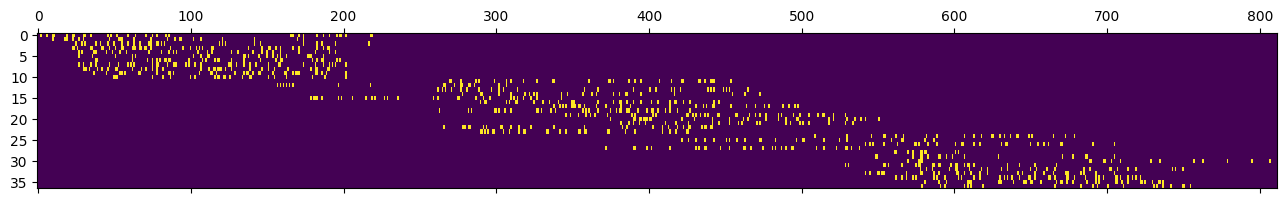

In [12]:
matshow(A_hs, aspect = 'auto')

### NN feasibility of mean-flattened Heartsteps data

First, we want to get a sense of how many observed (treated) values we have, since it seems that the treatment is applied relatively infrequently. If we have too few of these observed values, it could limit the number of potential neighbors that we could use to impute value.

In [271]:
nz_e = len(np.nonzero(A_hs)[0])
print("There are " + str(nz_e) + " nonzero entries")
print("The ratio of nonzero to zero entries is " + str(nz_e / (A_hs.size)))  

There are 1001 nonzero entries
The ratio of nonzero to zero entries is 0.03331780055917987


A $\sim \frac{1}{30}$ of zero to nonzero entries is pretty low. Let's see how it might affect average potential neighborhood size. To do this, we examine each zero entry in the masking matrix and consider how many possible neighbors could be used to impute it. Then we take the average number of possible neighbors.

In [37]:
total_pos_nn = 0
obs = np.nonzero(A_hs == 0)
for i in range(len(obs[0])): 
    total_pos_nn += np.sum(A_hs[obs[0][i], :])
print(total_pos_nn / len(obs[0]))
    

27.004958165478772


This might be slightly concerning, as the possible number of neighbors that could be used to impute this value is already quite small with no guarentees about closeness. 

## Li 2019 Nearest Neighbors Implementation

We implement the user-user nearest neighbors algorithm as defined in Nearest Neighbors for Matrix Estimation Interpreted as Blind Regression for Latent Variable Model (Li et al. 2019). More specifically, we construct Algorithm 2, which can be found in Section III [here](https://arxiv.org/abs/1705.04867).

First, to align the NN implementation with the data format considered above, we define a function to collapse the partitioned measurements dimension (3rd dim) to its mean.

In [13]:
def mean_collapse(A, d = 2):
    """
    Returns A (3d array) with dth dimension collapsed as mean
    """
    return np.nanmean(A, axis = d)

Next, we construct the necessary functions as defined in Li 2019.

In [14]:
def dissim_col(O, M, u, v):
    """
    Returns the col dissimilarity between cols u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a cols in O
    v : the index of a col in O

    Returns
    ----------
    d_col : the col dissimilarity between u and v (float)
    """
    obv_col_mask = M[:, u] * M[:, v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[:, u] - O[:, v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd
    
    
def dissim_row(O, M, u, v):
    """
    Returns the row dissimilarity between rows u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a row in O
    v : the index of a row in O

    Returns
    ----------
    d_row : the row dissimilarity between u and v (float)
    """
    obv_col_mask = M[u] * M[v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[u] - O[v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd

def nearest_neighbors(O_1, u, M, eta, variation = "user-user"):
    """
    Returns the B neighborbood around u using rows/cols in O_1 within
    radius eta. 
    
    Parameters
    ----------
    O_1 : a matrix of size c x d
    u : index of row/col u in O_1 and M
    M : a masking matrix of size c x d that
        dictates which entries of O_1 are known 
    eta : radius of B neighborhood
    variation : "user-user", "item-item" dictates which variation
                of nearest neighbors is being used. Default: "user-user"
    
    Returns
    ----------
    B : neighborhood (indicies of most similar rows/cols)
        with radius eta
    """
    if variation == "item-item":
        dissims = np.array([dissim_col(O_1, M, u, v) for v in range(len(O_1[0]))])
    else:
        dissims = np.array([dissim_row(O_1, M, u, v) for v in range(len(O_1))])        
    # remove u from neighbors
    #dissims = np.delete(dissims, u, 1)
    B = np.nonzero(dissims <= eta)
    return B
    
    
    
def estimate_li_nn(Z, M, eta):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    
    Returns
    ----------
    A_hat : the estimate of partially unobvserved matrix A
    """
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for u in range(m):
        for v in range(n):
            # sample splitting: artificially mask out values in the column of the
            # cell we are interested in
            O_1 = Z.copy()
            O_2 = Z[:, j]
            M_v = M.copy()
            M_v[:,j] = 0
            u_neighbors = nearest_neighbors(O_1, u, M_v, eta)
            # only select observed neighbors
            mask = M[u_neighbors, v]
            pos_nn = Z[u_neighbors, v]
            masked_nn = pos_nn[mask == 1]
            if not len(masked_nn):
                A_hat[u, v] = 0
            else:
                A_hat[u, v] = np.nanmean(masked_nn)
    return A_hat

def estimate_li_nn_inds(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (user-user variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
        # sample splitting: artificially mask out values in the column of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[:, j]
        M_j = M.copy()
        M_j[:,j] = 0
        u_neighbors = nearest_neighbors(O_1, u, M_j, eta)
        mask = M[u_neighbors, j]
        pos_nn = Z[u_neighbors, j]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
        
def estimate_li_nn_inds_cols(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (item-item variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
#         O_1  = np.delete(Z, u, axis = 0)
#         O_2 = Z[u, :]
#         M_j = np.delete(M, u, axis = 0)
        # sample splitting: artificially mask out values in the row of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[u, :]
        M_u = M.copy()
        M_u[u, :] = 0
        
        j_neighbors = nearest_neighbors(O_1, j, M_u, eta, variation = "item-item")
        mask = M[u, j_neighbors]
        pos_nn = Z[u, j_neighbors]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
# using the indexing strategy i am currently using, A_hat and A are both 1 dimensional. This might change.

def mse(A_hat, A):
    """
    Returns the mean squared error of estimate A_hat from ground truth A
    """
    return np.nanmean((A_hat - A)**2)

### Checking Li 2019 implementation correctness with worked example

In order to look for bugs in our cross validation and Li 2019 implementations, we create a sample dataset with some nice properties and compute the similarities by hand. This doesn't guarantee correctness, but it will catch simple errors/mistakes in understanding.

To start, we create a simulated datasest with 6 users over a two day trial period. There are 6 measurements per day and each day is broken into 3 segments. 3 of the users (A, B, and C) are similar to each other (roughly more steps in the evening/last measurement periods in the day) and the other 3 users (D, E, F) are different from the first 3 and similar to each other (roughly more steps in the morning/early measurement periods.  

Let's suppose the matrix is fully observed. To simulate a validation set, we mask out one segement for each user - these are the values we will try to impute.

In [15]:
# user inds
uA = np.repeat(1, 6 * 2)
uB = np.repeat(2, 6 * 2)
uC = np.repeat(3, 6 * 2)

uD = np.repeat(4, 6 * 2)
uE = np.repeat(5, 6 * 2)
uF = np.repeat(6, 6 * 2)

user_index = np.concatenate((uA, uB, uC, uD, uE, uF))

# step measurements
steps_uA = [1, 1, 2, 3, 5, 9, 1, 1, 3, 4, 5, 10]
steps_uB = [0, 2, 2, 4, 5, 11, 0, 2, 3, 3, 4, 12]
steps_uC = [0, 0, 2, 5, 7, 10, 2, 2, 1, 5, 6, 9]

steps_uD = [10, 5, 4, 3, 1, 1, 9, 5, 3, 2, 1, 1]
steps_uE = [12, 4, 3, 3, 2, 0, 11, 5, 4, 2, 2, 0]
steps_uF = [9, 6, 5, 1, 2, 2, 10, 7, 5, 2, 0, 0]
steps = np.concatenate((steps_uA, steps_uB, steps_uC, steps_uD, steps_uE, steps_uF))

# treatment indicators
trt_uA = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uB = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uC = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

trt_uD = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uE = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uF = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

single = pd.Series(pd.date_range("2024-06-14", "2024-06-16", inclusive = "left", freq = '4h'))

trt = np.concatenate((trt_uA, trt_uB, trt_uC, trt_uD, trt_uE, trt_uF))
final_np = np.stack((user_index, steps, trt), axis = 1)
df_nn_test = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
df_nn_test["date_time"] = pd.concat([single, single, single, single, single, single]).reset_index(drop = "True")
df_nn_test


,user.index,steps,treatment,date_time
0,1,1,1,2024-06-14 00:00:00
1,1,1,0,2024-06-14 04:00:00
2,1,2,1,2024-06-14 08:00:00
3,1,3,0,2024-06-14 12:00:00
4,1,5,0,2024-06-14 16:00:00
...,...,...,...,...
67,6,7,1,2024-06-15 04:00:00
68,6,5,1,2024-06-15 08:00:00
69,6,2,1,2024-06-15 12:00:00
70,6,0,0,2024-06-15 16:00:00


In [385]:
data_full, mask = transform_dnn_pad(df_nn_test, day_partitions = 3, day_measure = 6, units = 6, freq = "4h", range_begin = None)

In [386]:
data_full

array([[[ 1.,  1.],
        [ 2.,  3.],
        [ 5.,  9.],
        [ 1.,  1.],
        [ 3.,  4.],
        [ 5., 10.]],

       [[ 0.,  2.],
        [ 2.,  4.],
        [ 5., 11.],
        [ 0.,  2.],
        [ 3.,  3.],
        [ 4., 12.]],

       [[ 0.,  0.],
        [ 2.,  5.],
        [ 7., 10.],
        [ 2.,  2.],
        [ 1.,  5.],
        [ 6.,  9.]],

       [[10.,  5.],
        [ 4.,  3.],
        [ 1.,  1.],
        [ 9.,  5.],
        [ 3.,  2.],
        [ 1.,  1.]],

       [[12.,  4.],
        [ 3.,  3.],
        [ 2.,  0.],
        [11.,  5.],
        [ 4.,  2.],
        [ 2.,  0.]],

       [[ 9.,  6.],
        [ 5.,  1.],
        [ 2.,  2.],
        [10.,  7.],
        [ 5.,  2.],
        [ 0.,  0.]]])

In [387]:
mask

array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

First, we take the mean of the partitioned dimension to achieve the 2D structure.

In [388]:
data = mean_collapse(data_full)
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

Next, let's calculate the dissimilarities between each row. This is the mean squared difference between overlapping observed values. 

Dissim A-B: $\frac{((3 - 2.5)^2 + (1 - 1)^2 + (3.5 - 3.0)^2 + (7.5 - 8)^2)}{4} = \frac{0.75}{4} = 0.1874$

Dissim A-C: $\frac{(1-0)^2 + (3.5 - 2.5)^2 + (1)^2 + (0.5)^2 + 0^2}{4} = \frac{3.25}{4} = 0.8125$

Dissim A-D: $\frac{6.5^2 + 1^2 + 6^2 + 1^2 + 6.5^2}{5} = \frac{122.5}{5} = 24.5$

Dissim A-E: $\frac{0.5^2 + 6^2 + 7^2 + 6.5^2}{4} = 31.875$

Dissim A-F: $\frac{6.5^ + 0.5^2 + 7.5^2 + 0}{4} = 24.6875$ 

Dissim B-C: $\frac{0.5^2 + 0.5^2 + 1^2 + 0^2}{4} = 0.375$

Dissim B-D: $\frac{0.5^2 + 6^2 + 0.5^2 + 7^2}{4} = 21.375$

Dissim B-E: $\frac{0^2 + 7^2 + 7^2 + 0^2 + 7^2}{5} = 29.4$

Dissim B-F: $\frac{0^2 + 6^2 + 7.5^2 + 0.5^2}{4} = 23.125$

Dissim C-D: $\frac{7.5^2 + 0^2 + 5^2 + 0.5^2}{4} = 20.375$

Dissim C-E: $\frac{0.5^2 + 7^2 + 7^2 + 0^2}{4} = 24.5625$

Dissim C-F: $\frac{7.5^2 + 0.5^2 + 6.5^2 + 6.5^2 + 0.5^2}{5} = 28.25$

Dissim D-E: $\frac{0.5^2 + 1^2 + 0.5^2 + 0^2}{4} = 0.375$

Dissim D-F: $\frac{0^2 + 0.5^2 + 0.5^2 + 1^2}{4} = 0.375$

Dissim E-F: $\frac{0^2 + 1^2 + 0.5^2 + 0.5^2}{4} = 0.375$

We can see that A-B-C and D-E-F are two distinct neighborhoods with $\eta = 1$. Given this, we impute the missing values by taking the average of the neighbors at the column where an observation is missing. 

In [389]:
inv_mask = ~(mask.astype(bool))
mask


array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

In [390]:
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

In [391]:
data_imputed = data.copy()
data_imputed[0, 2] = 8.25
data_imputed[1, 0] = 0.5
data_imputed[2, 5] = 7.75
data_imputed[3, 2] = 1.5
data_imputed[4, 0] = 7.5
data_imputed[5, 5] = 1

In [392]:
# these are the imputed predictions
pred = data_imputed[inv_mask]
pred

array([8.25, 0.5 , 7.75, 1.5 , 7.5 , 1.  ])

In [393]:
# this is the ground truth
truth = data[inv_mask]
truth

array([7. , 1. , 7.5, 1. , 8. , 0. ])

In [394]:
# the mse is:
mse(pred, truth)

[ 1.25 -0.5   0.25  0.5  -0.5   1.  ]


0.5625

When we compute the MSE of the prediction by hand following Li 2019's method, we get 0.5625. Now we compute it using our implementation.

In [395]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds(data_full, mask, eta = 1, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

[ 1.25 -0.5   0.25  0.5  -0.5   1.  ]


0.5625

Now, we compute the same predictions for the item-item strategy.

In [396]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds_cols(data_full, mask, eta = 3, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

[51.25  13.75   0.    45.625 15.375  0.   ]
[ 0.     12.6875 51.25    1.3125 14.0625 42.25  ]
[42.25   15.0625  0.     44.0625 11.8125  0.    ]
[51.25  13.75   0.    45.625 15.375  0.   ]
[ 0.     12.6875 51.25    1.3125 14.0625 42.25  ]
[42.25   15.0625  0.     44.0625 11.8125  0.    ]
[0.5 0.  1.  0.  0.  2. ]


0.875

## Cross Validation for $\eta$

Next, we implement cross-validation for the $\eta$ radius parameter. Given a dataset, an error metric, and an estimation function, we evaluate a range of values of $\eta$. 

In [ ]:
# notes
    # we are only interested in the estimates that `estimate` makes for the
    # validation set in particular. For any validation fold, we must only consider observed values (need a ground truth)
    # We mask over these values to estimate, then extract the estimates using the original mask to compute the error.
    
# pick one cell to impute for the heartsteps to check correctness for Li 2019

In [397]:
def cross_validate_nn(Z, M, k, eta, estimate, error_metric):
    """
    Performs k-fold cross validation on using dataset `Z`, mask `M`, parameters `k` and `eta`,
    estimation function `estimate`, and error `error_metric`
    """
    # find observed indices and create splits off of those
    obvs_inds_x, obvs_inds_y = np.nonzero(M)
    
    # shuffle the x and y coordinates in the same way to maintain valid coords
    shuf_inds = np.arange(len(obvs_inds_x))
    np.random.shuffle(shuf_inds)
    shuf_obvs_inds = np.array((obvs_inds_x[shuf_inds], obvs_inds_y[shuf_inds]))
    # split coordinates into k-folds
    folds = np.array_split(shuf_obvs_inds, k, axis = 1)
    tot_error = 0
    for i in range(k):
        # indices of the observed outcomes in the validation set in this iteration
        folds_ind = tuple(folds[i])
        # ground truth
        val_data = mean_collapse(Z[folds_ind], d = 1)
        est_mask = M.copy()
        # hide observed values in the validation set
        est_mask[folds_ind] = 0
        A_hat = estimate(Z, est_mask, eta, folds_ind)
        # extract validation points
        est_val = A_hat[folds_ind]
        err = error_metric(est_val, val_data)
        print(err)
        tot_error += err
    # return average error over k folds
    return tot_error / k
 

### Cross validation for Li (2019) NN

We use k-fold cross validation to tune hyperparameter $\eta$ for the Li (2019) NN model implemented above. We show results using k = 5 and k = # observed outcomes (LOOCV). 

In [411]:
# first, compute dissims from a subsection of the data to get a sense of the range of distances
# notation: should change later, but M_hs is Z and A_hs is M
from itertools import product
rnd_ind = np.random.choice(37, size = 10, replace = False)
all_combs = product(rnd_ind, rnd_ind)
M_hs_collapse = mean_collapse(M_hs)
for u, v in all_combs:
    print(dissim_row(M_hs_collapse, A_hs, u, v))

0.0
4868.120563271604
inf
inf
470.72260802469145
30933.782793209873
inf
inf
inf
inf
4868.120563271604
0.0
inf
inf
14719.209876543207
24777.187757201646
inf
inf
inf
inf
inf
inf
0.0
1628.8205667789
inf
inf
815.2448559670784
inf
2193.5417952674898
inf
inf
inf
1628.8205667789
0.0
inf
inf
1252.1514917695472
inf
3589.6874142661177
4976.187499999999
470.72260802469145
14719.209876543207
inf
inf
0.0
20618.119212962967
inf
inf
inf
2471.5918209876536
30933.782793209873
24777.187757201646
inf
inf
20618.119212962967
0.0
inf
inf
inf
4.0
inf
inf
815.2448559670784
1252.1514917695472
inf
inf
0.0
inf
9157.41335978836
11094.676697530866
inf
inf
inf
inf
inf
inf
inf
0.0
inf
inf
inf
inf
2193.5417952674898
3589.6874142661177
inf
inf
9157.41335978836
inf
0.0
850.7935956790122
inf
inf
inf
4976.187499999999
2471.5918209876536
4.0
11094.676697530866
inf
850.7935956790122
0.0


C:\Users\Caleb\AppData\Local\Temp\ipykernel_9804\3608872350.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


In [410]:
# try using HeartSteps data with eta 10 to 500? are there other hyperparameter optimizations to use? 
# k = 5
eta_range = np.arange(10, 1500, step = 10)
#eta_range = [350.]

min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 5, eta, estimate_li_nn_inds, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta


C:\Users\Caleb\AppData\Local\Temp\ipykernel_9804\3608872350.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


[ -20.66666667  -12.11111111  -25.52777778   -8.52777778  -13.66666667
   -5.27777778 -125.30555556  -61.83333333  -10.88888889  -18.13888889
  -56.72222222  -12.05555556 -194.77777778  -14.05555556 -114.25
  -22.58333333  -39.44444444  -22.91666667  -83.83333333  -12.55555556
  -30.97222222  -53.02777778  -53.75        -38.          -68.86111111
    0.          -25.91666667  -49.44444444  -54.61111111   -9.13888889
   -0.52777778   -3.94444444  -70.63888889  -23.83333333  -70.75
  -54.58333333  -81.83333333  -21.5         -36.47222222  -68.72222222
 -166.44444444   -7.94444444    0.          -32.38888889  -73.13888889
  -27.58333333  -22.58333333  -31.11111111 -224.61111111  -19.47222222
 -174.25        -22.66666667 -152.5         -24.22222222  -28.91666667
   -4.72222222  -12.41666667  -94.33333333  -38.22222222  -22.19444444
   -8.77777778  -73.25        -38.77777778  -22.19444444  -58.97222222
  -32.86111111  -37.88888889  -74.16666667   -6.36111111  -65.13888889
  -29.33333333 -10

[-158.88888889  -28.83333333  -18.47222222 -179.44444444  -16.41666667
  -45.19444444  -89.83333333  -18.05555556  -63.5         -32.63888889
  -45.75         -4.83333333  -48.63888889  -24.22222222  -10.30555556
  -18.02777778   -9.5        -131.97222222  -25.63888889  -23.63888889
  -30.44444444 -160.16666667  -29.33333333  -18.91666667  -27.
  -74.86111111  -31.5          -9.94444444  -11.61111111  -18.69444444
  -54.86111111   -4.88888889  -10.86111111  -11.58333333  -47.66666667
  -23.05555556  -15.55555556  -27.          -27.38888889 -110.05555556
  -61.38888889  -36.05555556  -49.11111111   -3.05555556  -14.47222222
  -27.83333333  -99.          -22.97222222  -29.36111111  -23.13888889
  -30.91666667  -24.72222222   -7.75        -13.80555556 -162.58333333
    0.         -229.22222222  -87.52777778  -12.25        -38.25
  -86.88888889    0.           -8.80555556 -133.05555556  -68.30555556
  -40.69444444 -242.16666667  -37.75         -9.97222222 -478.08333333
  -25.          -31.

[-2.21944444e+01 -1.05722222e+02 -6.11111111e-01 -1.03944444e+02
 -9.31944444e+01  0.00000000e+00 -1.96944444e+01 -1.06555556e+02
 -2.78888889e+01 -1.91944444e+01 -3.41111111e+01 -2.28333333e+01
 -9.72222222e-01 -2.60000000e+01 -2.64500000e+02 -9.44444444e-01
 -1.38611111e+01 -5.00000000e-01 -3.21111111e+01 -8.16666667e+01
 -2.28611111e+01  0.00000000e+00 -1.49222222e+02 -2.78333333e+01
 -4.42777778e+01 -5.50555556e+01 -5.83888889e+01 -1.36666667e+01
 -5.28888889e+01 -9.90000000e+01 -1.73611111e+01 -3.33611111e+01
 -1.56944444e+01 -2.56388889e+01 -1.04722222e+01 -1.80277778e+01
 -6.66666667e-01 -6.68888889e+01 -1.37222222e+01 -2.55555556e+01
 -1.44444444e+01 -2.73055556e+01  5.73888889e+01 -2.90833333e+01
 -2.58333333e+00 -2.88888889e+01 -5.07500000e+01 -2.10833333e+01
 -2.38333333e+01 -1.74305556e+02 -3.09444444e+01 -1.37500000e+01
 -3.24444444e+01 -2.75833333e+01 -6.14166667e+01 -9.33333333e+01
 -3.23611111e+01 -4.26666667e+01 -8.13888889e+00 -4.27500000e+01
 -2.41944444e+01 -1.15833

[   0.          -28.27777778  -71.55555556  -18.30555556  -69.02777778
  113.58333333   -0.66666667   -0.61111111  -32.38888889  -34.11111111
  -29.36111111  -47.41666667  -70.05555556   -5.91666667  -18.91666667
  -62.47222222  -27.          -14.77777778  -65.11111111  -12.05555556
   -8.69444444   -3.94444444  -51.13888889  -55.52777778  -37.52777778
  -78.19444444  -64.25        -16.80555556  -34.41666667  -50.47222222
  -26.          -52.88888889  -62.66666667  -33.11111111  -41.66666667
  -29.33333333  -81.38888889  -29.33333333  -18.55555556  -73.91666667
 -124.38888889   -8.16666667    0.          -46.38888889  -61.41666667
  -43.63888889  -80.25       -217.19444444   -8.61111111  -22.41666667
  -83.88888889  -13.66666667  -36.           -3.5         -16.25
  -10.30555556  -24.22222222  -17.88888889  -20.36111111  -61.30555556
  -42.83333333  -28.97222222  -52.27777778 -171.27777778  -29.36111111
  -23.83333333  -21.75       -175.25        -27.22222222 -102.11111111
    2.472222

...

[ -18.55555556   -9.55555556  -39.72222222    0.          -65.22222222
  -49.44444444 -185.5        -242.63888889  -12.41666667    0.
   47.63888889    0.          -24.83333333  -73.25        -79.16666667
    0.          -63.5         -71.86111111   19.58333333  -21.22222222
  -61.41666667   40.27777778  -31.27777778   -6.58333333   -2.30555556
  -18.72222222   20.94444444  -75.27777778   12.25          2.61111111
 -106.55555556   36.44444444   12.69444444   56.60185185  -85.83333333
  -87.83333333  -23.          -93.88888889   17.66666667    0.
  -48.72222222  -44.05555556 -250.86111111   12.36111111  -55.27777778
  -17.52777778   20.98611111 -107.08333333  -36.47222222   -9.66666667
   23.73611111  -27.16666667   44.69444444   12.95833333   64.13888889
  -16.33333333  -88.88888889   -9.33333333  -52.83333333  -22.11111111
 -112.25         -6.16666667   36.33333333  -77.11111111   39.80555556
   -1.91666667  -10.41666667  -31.52777778  -22.30555556  -29.02777778
  -78.33333333  -40.16

[ -39.55555556  -13.91666667  -17.69444444 -121.93518519  -64.25
  -31.41666667 -179.44444444  -25.52777778   -9.73611111  -29.36111111
  -55.41666667 -114.25          2.13888889  -33.69444444  -24.16666667
  -29.08333333  -61.38888889 -176.          -40.41666667  -23.77777778
   21.33333333  -62.52777778  -68.44444444 -112.72222222  -23.30555556
   -3.94444444   -5.83333333   57.38888889    3.72222222    0.
 -116.97222222 -257.63888889  -64.63888889   -7.36111111   -6.33333333
    0.           -0.75         56.88888889  -35.          -29.55555556
  -16.63888889   11.83333333   64.38888889   20.83333333   70.68055556
  -47.77777778   34.55555556   67.13888889  -19.25        -79.16666667
  -70.33333333   -5.30555556   25.97222222  -71.72222222   51.83333333
   -7.27777778  -26.02777778  -28.91666667 -242.16666667  -96.33333333
  -60.13888889    6.72222222  -87.22222222  -38.11111111  -52.27777778
  -82.27777778    1.13888889 -162.61111111  -33.75         -0.56944444
   41.97222222  -63.

[-4.49166667e+01  5.04166667e+01  1.66666667e-01 -9.29722222e+01
 -3.39722222e+01 -8.25000000e+01 -2.63888889e+01 -6.52222222e+01
  5.68611111e+01 -9.75000000e+00 -1.05277778e+02 -2.66111111e+01
 -1.86944444e+01 -2.36944444e+01 -8.80555556e+00  6.25277778e+01
  2.24166667e+01  7.39444444e+01 -7.58333333e+00 -3.15277778e+01
  3.47777778e+01 -1.90250000e+02 -1.65277778e+01 -3.75000000e+00
  7.11111111e+00 -8.50000000e+00 -1.64722222e+01 -2.47222222e+01
 -2.53888889e+01 -6.17500000e+01 -5.52777778e+00 -5.34444444e+01
 -1.34166667e+01 -3.20833333e+01 -2.62500000e+01 -3.80555556e+00
 -7.02222222e+01 -1.15833333e+01 -1.27833333e+02  2.15555556e+01
 -4.27500000e+01  1.51944444e+01 -2.42638889e+02 -1.89166667e+01
 -4.63888889e+01  6.19444444e+01 -2.30555556e+01 -4.67777778e+01
  3.64722222e+01  3.66111111e+01 -9.72500000e+01  4.45000000e+01
 -7.15833333e+01  3.83333333e+00 -6.55555556e+00 -4.90833333e+01
 -3.60000000e+01 -2.27777778e+01 -5.18888889e+01 -1.36527778e+01
 -3.82500000e+01  8.58055

[ -11.58333333  -10.44444444    9.22222222   21.02777778  -56.72222222
  -36.           54.97222222 -111.44444444   -2.58333333  -18.72222222
   43.69444444  -90.25        -62.22222222  -26.38888889  -73.05555556
  -49.44444444  -29.61111111  -11.66666667   25.5         -97.63888889
  -31.52777778  -70.30555556 -229.22222222  -41.94444444  -18.91666667
  -38.11111111   -7.94444444  -94.33333333  155.          -28.27777778
  -17.88888889   69.58333333  -71.55555556 -104.11111111   22.41666667
  -82.41666667   -7.52777778  -31.75        -10.36111111  -12.66666667
  -44.69444444  -43.80555556  -11.34722222  -16.63888889   45.19444444
    0.         -134.16666667   31.41666667  -44.25        -13.91666667
  -33.69444444  -25.88888889   -7.88888889  -26.38888889  -16.77777778
  -25.68055556  -61.75       -242.86111111   23.77777778  -27.
 -129.47222222  -65.22222222   -4.83333333    0.          -21.08333333
  -24.16666667  107.38888889 -215.47222222  -76.66666667   -8.13888889
 -115.66666667

[  -5.83333333  -23.91666667  -69.69444444  -21.22222222  -39.05555556
   -9.5        -217.19444444  -14.41666667   26.58333333    1.86111111
  -16.41666667  -24.36111111   -2.30555556  -76.66666667  -23.61111111
   -5.77777778  -68.41666667  -29.33333333  -18.91666667    0.
  -19.69444444  -25.88888889  -50.02777778  -22.66666667  -38.77777778
 -102.11111111    8.58333333   -8.80555556   -9.86111111  -84.27777778
  -26.          -35.27777778  -28.27777778 -130.27777778  133.77777778
  -17.41666667  -27.11111111   -5.13888889  -56.75        -97.63888889
  -36.05555556  -32.66666667   18.55555556  -16.38888889   46.01388889
  -20.08333333  -18.08333333   -9.5         -32.22222222   -9.33333333
   -5.30555556  -55.13888889  -30.83333333   -0.5          24.
 -241.58333333  -52.69444444 -127.90277778  -16.69444444    0.
  -60.63888889  -11.38888889  -29.33333333    0.          -31.02777778
 -175.25        -42.97222222   38.           44.91666667  -12.66666667
   18.77777778  -41.22222222  

In [415]:
best_eta
min_error

4089.9982951235334

In [87]:
# k = # observed entries
k = len(np.nonzero(A_hs)[0])
min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 50, eta, estimate_li_nn_inds, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta

<class 'float'>
[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

...

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

[[[  0.   0.   0. ...   0.  26.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...  68.  25.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  42.   0.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  24.  18.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 ...

 [[  0.   0.   0. ...   0.   0. 296.]
  [218.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.  22.  66.]
  ...
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.   0. ...   0.   0.   0.]]

 [[  0.   0.   0. ...   0.   0.   0.]
  [  0.   0.

In [27]:
best_eta

440

## Testing Li 2019 on Overlapping Data in Heartsteps

The key motivation behind this section is in the patterned missingness observed in the Heartsteps data. First, we select a reasonably large section of data that will allow us to simulate the overlap between two groups of people.

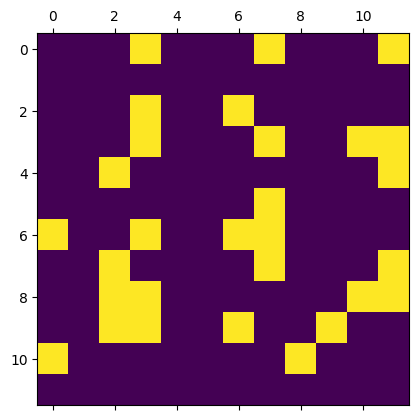

In [59]:
matshow(A_hs[0:12, 180:192], aspect = 'auto')
# A_hs_sub = A_hs[10:30, 424:444]
# M_hs_sub = M_hs[10:30, 424:444]

A_hs_sub = A_hs[0:12, 180:192]
M_hs_sub = M_hs[0:12, 180:192]

In [17]:
# Search for "densest" area of observed values in the data
# define density as the number of observed values over the area of the square.
# square area 15 x 15
from numpy.lib.stride_tricks import as_strided
max_unit = 0
global_max_density = 0
max_matrix = None
for j in [20]:
    sub_shape = (j, j)
    view_shape = tuple(np.subtract(A_hs_sub.shape, sub_shape) + 1) + sub_shape
    arr_view = as_strided(A_hs_sub, view_shape, A_hs_sub.strides * 2, writeable = False)
    arr_view = arr_view.reshape((-1,) + sub_shape)
    max_dense = 0
    ind_max_dense = 0
    for i in range(len(arr_view)):
        density = np.sum(arr_view[i]) / (j * j)
        if density > max_dense:
            max_dense = density
            ind_max_dense = i

    if max_dense > global_max_density:
        max_matrix = arr_view[ind_max_dense]
        global_max_density = max_dense
        max_unit = j
        
    print(max_dense)
    print(ind_max_dense)

ValueError: negative dimensions are not allowed

In [18]:
print(max_unit)
print(global_max_density)
print(max_matrix)

0
0
None


One of the largest/most dense regions in the dataset is `A_hs_sub` as described above. We use this data to compare user-user and item-item approaches in "overlapping" regions. These are regions in which there is an L-shaped pattern of observed data. At the corner of this L, there is a set of values that could benefit from imputation using either user information along subset of the L or item information along the opposing subset. We simulate this scenario using a dense region of the matrix as a proof of concept.

In [60]:
# the lower right corner will be the test set (9x9)
tst_x_beg = len(A_hs_sub[0]) - 5 # cols
tst_x_end = len(A_hs_sub[0])
tst_y_beg = len(A_hs_sub) - 5 # rows
tst_y_end = len(A_hs_sub)

test_set_A = A_hs_sub[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end]
test_set_M = M_hs_sub[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end]
print(test_set_A)
#print(test_set_M)

[[1 0 0 0 1]
 [0 0 0 1 1]
 [0 0 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]


To set up our process, we take the segment immediately to the left of the test segment and use cross validation to tune $\eta$ with the item-item NN variations. Then, we use the tuned $\eta$ to estimate values in the test set using only the block to the left and the test square. We repeat the process for the segment immediately above the test square and with the user-user variation. Finally, we compare test errors between the two segments.

In [63]:
# item-item with "bottom" sub-chunk

# mask all other indices to cross-validate on just the sub-chunk
A_subc_b = A_hs_sub.copy()
A_subc_b[:,: tst_x_beg] = 0
A_subc_b[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end] = 0
# k = 5
# eta_range = np.arange(10, 1500, step = 10)
# #eta_range = [350.]

# min_error = float("inf")
# best_eta = 0
# for eta in eta_range:
#     error = cross_validate_nn(M_hs, A_subc_b, 5, eta, estimate_li_nn_inds, mse)
#     print("Error for eta " + str(eta) + ": " + str(error))
#     if error < min_error:
#         min_error = error
#         best_eta = eta
A_subc_b

array([[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

## Kernel NN/MMD Implementation

We take the same data format as implemented in `transform_dnn` above. Unlike Li (2019), we do not wish to aggregate the measurements in each unit x time cell as a mean. Instead, we will use them to approximate the distribution from which they were drawn. Since we do not have the true distributions of any of the entries, we can validate our performance.


In [139]:
# might need more clarification on how MMD works with empirical distributions, i.e. how to find
# order statistics or values to impute etc..

In [137]:
def mmd_sqd(X_i, X_j, kern):
    """
    Return the MMD^2 distance between rows with n measurements in each cell
    X_i and X_j
    
    Parameters:
    ----------
    X_i : (T - 1) x n matrix
    X_J : a T - 1) x n matrix
    kern : kernel function
    """
    sum_h = 0
    for l, l_p in itertools.combinations(range(len(X_i)), r=2):
        print(f"{i}, {j}")
        x = X_i[l]
        x_p = X_i[l_p]
        y = X_j[l]
        y_p = X_k[l_p]
        sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y)
    n = len(X_i)
    return (1 / (n * (n - 1)) * sum_h)
        
    
def dissim_mmd(X, A, i, j, kern):
    """
    Measures the dissimilarity between rows i and j using maximum mean discrepancies (MMD)
    
    Parameters: 
    ----------
    X : N x (T - 1) x n array
    A : N x (T - 1) matrix that denotes which entries of X are observed
    i : indice of a row in X
    j : indice of row in X
    kern : kernel function
    """
    full_mask = A[i] * A[j]
    overlap = np.sum(full_mask)
    if not overlap:
        return float("inf") 
    mmd_dissims = mmd_sqd(X[i], X[j], kern) 
    return np.sum(mmd_dissims * full_mask) / overlap
            
def mmd_barycenter(X, A, i, t, eta):
    """
    Compute the squared MMD barycenter
    """
    
    #concatenated = chain(range(50), range(51, 100))
    # idk at the moment
    #for i in concatenated
    # unsure about u statistic in MMD code
    dissims = dissim_mmd(X, A, )
    neighborhood = 

## Optimal Transport/Wasserstein Implementation

In [ ]:
# Wassertein distance -> the barycenter is described by its order statistics, which we use as
# our estimates for imputation? it seems like it becomes the mean of the (sorted)
# neighbors at the measurement level in the empirical case

In [ ]:
# is the empirical barycenter just the order statistics on the distribution, which are in turn the average of the measurements across columns?
def wasserstein2_dist(Y, A, u, i):
    """
    Return Wasserstein_2^2 distance between row u and row i of 
    observed entries in array Y

    Parameters: 
    ----------
    Y : (M + 1) x (N + 1) x n array
    A : (M + 1) x (N + 1) masking array that denotes which entries of X are observed
    u : indice of row in Y
    i : indice of row in Y
    """